<img src="https://github.com/GJay99/Trabajos_APS/blob/master/TS0/logo_UNSAM.jpg?raw=1" align="right" width="150" />

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº7
#### Gonzalo Jay y Sofía Makkos

# Introducción
En el presente trabajo se desarrollarán distintos tipos de filtrados digitales, con el fin de mitigar fuentes de contaminación tanto de alta como de baja frecuencia. Para esto, se emplearán filtros *FIR* (Respuesta al Impulso Finita) e *IIR* (Respuesta al Impulso Infinita). A modo de comparación, se realizó la siguiente tabla:

$$
\begin{array}{|c|l|l|}
\hline
\textbf{} & \textbf{FIR} & \textbf{IIR} \\
\hline
\textbf{Duración} & \text{Contiene una cantidad finita de impulsos en un rango limitado} & \text{Tiene respuestas al impulso de duración temporal infinita} \\
\hline
\textbf{Salida}   & \text{Usualmente, depende únicamente de los valores anteriores y} & \text{Depende tanto de los valores anteriores y presentes de la entrada} \\
                  & \text{presentes de la entrada} & \text{como de los valores anteriores de la salida} \\
\hline
\textbf{Retardo} & \text{Cuenta con retardo de grupo constante con una misma demora} & \text{Genera una distorción en la fase (no necesariamente lineal)} \\
                  & \text{(fase lineal)} \\
\hline
\textbf{Estabilidad} & \text{Estable, debido a sus polos en cero} & \text{La estabilidad depende de los coeficientes del sistema} \\
\hline
\textbf{Causalidad} & \text{Causal $\Longrightarrow$ Prospectivos} & \text{Generalmente Anticausal $\Longrightarrow$ Retrospectivos} \\
\hline
\textbf{Ventajas} & \text{Aplicable en tiempo real} & \text{Generalmente, tiene órdenes menores a sus filtros FIR equivalentes,} \\
                  & &\text{lo que lleva a menos operaciones computacionales y menos memoria} \\
                  & &\text{a implementar. También tienen menor latencia} \\
\hline
\textbf{Desventajas} & \text{Tiene un costo computacional más alto, debido a la} & \text{No utilizable en tiempo real} \\
                  & \text{convolución de N muestras, lo cuál genera también} \\ 
                  & \text{un mayor retardo} \\
\hline
\end{array}
$$

Luego, para cada tipo de sistema, también existen diferentes métodos de implementación. En cuanto a los IIR, se emplearán los filtros Butterworth/máxima planicidad, Chebyshev y Cauer/elípticos, los cuales se basan en prototipos de filtros análogos. 
- Butterworth: se caracteriza por decrecer de manera monotónica a medida que incrementa la frecuencia $\Omega$ para cualquier valor de *N*. A la respuesta se la denomina de máxima planicidad, siendo que la pendiente a $\Omega=0$ es nula.
- Chebyshev: se distingue en la magnitud de la respuesta en frecuencia por un comportamiento de equiripple en la banda de paso (Tipo I) o en la banda de stop (Tipo II o Inverso). La respuesta es monotónica en la zona opuesta (banda de stop para Tipo I y banda de paso para Tipo II). La magnitud oscila y la amplitud pico a pico es constante a lo largo de toda la banda.
- Elíptico: cuenta con un equiripple tanto en la banda de paso como en la de stop, y la magnitud de ripple en cada zona es independiente a la otra.

A la vez, los FIR se distinguirán en aquellos basados en ventanas, en cuadrados mínimos y en diseño óptimo.
- Ventanas: se modifica la respuesta del filtro pasabajos deseado multiplicando a este por una función ventana *w[n]*
\begin{equation}
h[n]=h_{ideal}.w[n]
\end{equation}
- Cuadrado mínimo: se calculan aquellos coeficientes del filtro que resulten en la menor diferencia posible entre la señal deseada y la salida real. Se aplica un factor de ponderación $W(\omega_k)$
- Diseño óptimo: también denominados filtros equiripple. Presentan magnitud de la respuesta en frecuencia con ripple tanto en la banda de paso como en la de stop, cada una con su amplitud idéntica a lo largo de su zona. En esta ocasión, se implementará el filtro Parks–McClellan

Una de las finalidades de esta experimentación con los filtros consiste en la mitigación de elementos indeseados en una señal ECG conocida. Para esto, se deberán definir ciertos parámetros, como las frecuencias de paso *wp* (riple) y de stop *ws*. Las atenuaciones de paso *Gp* y de stop *Gs*. Al electrocardiograma se le aplicará un filtro pasa banda, por lo tanto, se requerirán cuatro frecuencias distintas. Además, mediante ciertas regiones de interés del ECG, se analizará la efectividad del filtrado de perturbaciones de la señal y la omisión de elementos no interferentes.

# Desarrollo
Importamos todas las librerías necesarias para la resolución de esta tarea semanal. Dentro de las mismas es necesario destacar *scipy.signal*, la cual incluye las herramientas necesarias tanto para el diseño como implementación de los distintos filtros.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from matplotlib.patches import Rectangle
import scipy.io as sio

También leeremos el archivo donde se encuentra digitalizada la señal de ECG ruidosa, de la misma manera que ya lo hicimos en la TS5. Fue necesario castear los datos a un tipo Float64 y utilizar la función *flatten* para eliminar una dimensión extra vacía que tenía el vector de datos. Ambos procesos fueron necesarios para asegurar el correcto funcionamiento de las funciones posteriores.

In [2]:
fs_ecg = 1000

sio.whosmat('ECG_TP4.mat')
mat_struct=sio.loadmat('./ECG_TP4.mat')

ecg_one_lead_audio =mat_struct ['ecg_lead'] * 1.0
ecg_one_lead_audio = ecg_one_lead_audio.flatten()

Procedemos a graficar el electrocardiograma. 

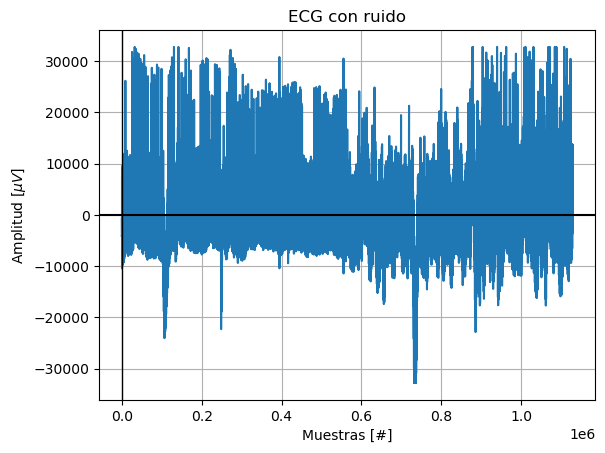

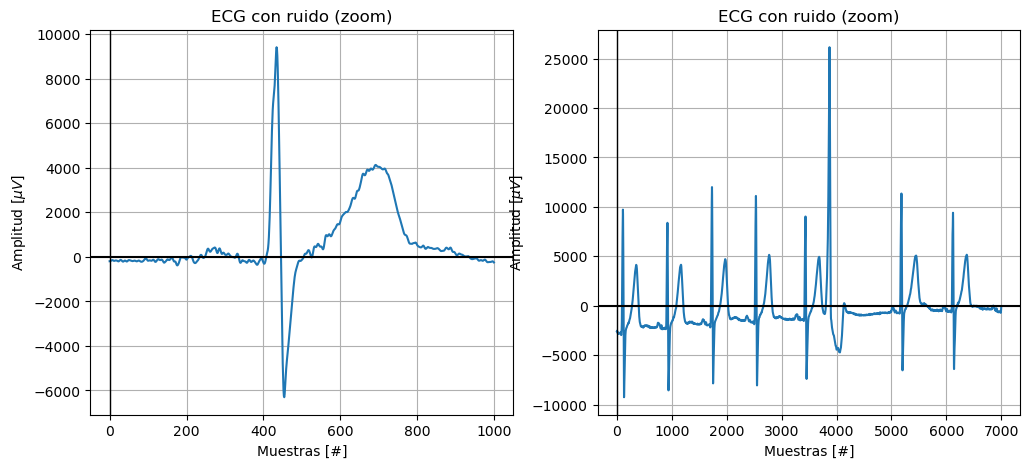

In [3]:
plt.figure(1)
plt.plot(ecg_one_lead_audio)

plt.title("ECG con ruido")
plt.xlabel("Muestras [#]")
plt.ylabel("Amplitud [$\mu V$]")

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()

plt.figure(2, figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(ecg_one_lead_audio[50000:51000])

plt.title("ECG con ruido (zoom)")
plt.xlabel("Muestras [#]")
plt.ylabel("Amplitud [$\mu V$]")

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()

plt.subplot(1,2,2)
plt.plot(ecg_one_lead_audio[5000:12000])

plt.title("ECG con ruido (zoom)")
plt.xlabel("Muestras [#]")
plt.ylabel("Amplitud [$\mu V$]")

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()

## Diseño de plantilla
Como idea base, se decidió que el filtro a diseñar debía ser un filtro pasa-banda, donde se buscará eliminar el ruido de continua, es decir frecuencia 0 Hz, y el ruido de alta frecuencia. Esto lo decidimos, principalmente, en base de los periodogramas realizados en la TS5, donde pudimos ver cómo en el ECG con ruido existía un fuerte componente de continua que no existía en el sin ruido, además de que pudimos demostrar que el ancho de banda del mismo era de 1 a 35 Hz, lo que concuerda con lo esperado teóricamente.

Por otro lado, también lo podemos apreciar observando los gráficos con zoom del electrocardiograma. En el primero, se aprecia cómo a la forma conocida de los complejos P-QRS-T se le agregan oscilaciones pequeñas de muy alta frecuencia. Por el otro lado, en la figura de la derecha se aprecia cómo existe un ruido de baja frecuencia que provoca desviaciones en el valor medio, el cuál no solo no es cero si no que varía a lo largo de la señal.

Resumiendo nuestro criterio de diseño, consideramos que el filtro debería permitir el paso de frecuencias entre 1 Hz y 35 Hz, debiendo tener una transición rápida en las frecuencias bajas que permita el correcto filtrado del ruido de este tipo, y una transición mas relajada del otro lado del espectro al no tener ninguna restricción.

Por el lado de las atenuaciones el criterio de selección no fue tan profundo. Simplemente se eligió $G_p$ en función a la definición usual de que la banda de paso de un filtro se encuentra en la zona donde la atenuación es menor a 3 dB, mientras que la $G_s$ no tiene un criterio relevante a aplicar, por lo que 40 dB nos pareció una atenuación suficiente para suponer que esa componente no afectará a la señal.

In [4]:
ws1 = 0.1
wp1 = 1
wp2 = 35
ws2 = 40
wp = [wp1,wp2]
ws = [ws1,ws2]

G_p = 3
G_s = 40

## Diseño filtros IIR
Lo primero que hicimos fue generar una función genérica capaz de realizar el diseño de los distintos filtros de Respuesta al Impulso Infinita mediante la creación de distintos bloques SOS. Esta función requiere que se le indique las frecuencias de pass, stop, sus ganancias, la frecuencia de sampleo y qué aproximador matemático deseamos utilizar. La misma retornará tanto los coeficientes de cada bloque SOS como el módulo, fase y retardo que tendrán estos filtro a las distintas frecuencias.

In [5]:
def filtro_IIR(wp, ws, G_p, G_s, aproximador, ff, fs):
    sos = signal.iirdesign(wp, ws, G_p, G_s, ftype = aproximador, output = 'sos', fs=fs)
    f, H = signal.freqz_sos(sos,worN = ff, fs = fs)
    modulo = np.abs(H)                 
    fase = np.unwrap(np.angle(H))
    w = 2 * np.pi * f
    retardo = -np.gradient(fase, w)
    return sos, f, modulo, fase, retardo

Ahora utilizamos la función para realizar un filtro con cada uno de los aproximadores estudiados en clase.

In [6]:
ff = np.append(np.logspace(np.log10(0.001),np.log10(1),2000),np.linspace(1.001,35,2000))
ff = np.append(ff,np.logspace(np.log10(35.001),np.log10(45),2000))
ff = np.append(ff,np.linspace(45.1,fs_ecg/2,2000))

In [7]:
sos_butter, f_butter,modulo_butter, fase_butter,retardo_butter = filtro_IIR(wp, ws, G_p, G_s, 'butter', ff, fs_ecg)
sos_ellip, f_ellip,modulo_ellip, fase_ellip,retardo_ellip = filtro_IIR(wp, ws, G_p, G_s, 'ellip', ff, fs_ecg)
sos_cheby, f_cheby ,modulo_cheby, fase_cheby,retardo_cheby = filtro_IIR(wp, ws, G_p, G_s, 'cheby2', ff, fs_ecg)

Continuamos con la realización de las figuras de la respuesta en frecuencia de los 3 filtros, donde podremos analizar si los mismos efectivamente cumplen con los criterios de diseño que tuvimos o las restricciones fueron demasiado estrictas.

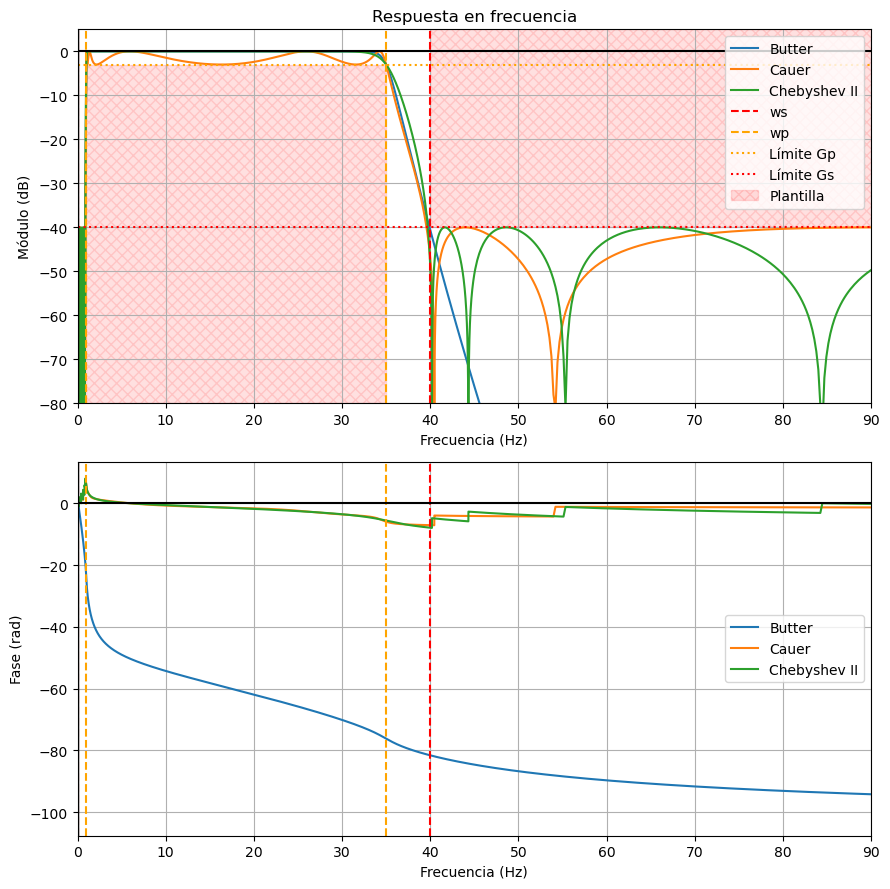

In [8]:
plt.figure(3, figsize=(9,9))

plt.subplot(2,1,1)

plt.plot(f_butter, 20*np.log10(np.maximum(modulo_butter, 1e-12)),label="Butter")
plt.plot(f_ellip, 20*np.log10(np.maximum(modulo_ellip, 1e-12)),label="Cauer")
plt.plot(f_cheby, 20*np.log10(np.maximum(modulo_cheby, 1e-12)),label="Chebyshev II")

plt.title("Respuesta en frecuencia")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(ws1, color="red", linestyle="--", label="ws")
plt.axvline(wp1, color="orange", linestyle="--", label="wp")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-80, 5)
y_min, y_max = plt.ylim()

plt.fill_between([0, ws1], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.fill_between([ws2, fs_ecg/2], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.xlim(0, ws2+50)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()


plt.subplot(2,1,2)

plt.plot(f_butter, fase_butter, label="Butter")
plt.plot(f_ellip, fase_ellip, label="Cauer")
plt.plot(f_cheby, fase_cheby, label="Chebyshev II")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.ylabel("Fase (rad)")
plt.xlabel("Frecuencia (Hz)")
plt.xlim(0, ws2+50)

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

plt.tight_layout()

A simple vista, pareciera que todos los filtros cumplen con las condiciones planteadas. Además, mientras que Cauer y Chebyshev presentan picos que vuelven a tocar el limite de atenuación mínima en la banda de stop, Butterworth sigue hasta mucho más abajo donde se estabiliza. Realizamos zoom a la baja frecuencia para comprobar.

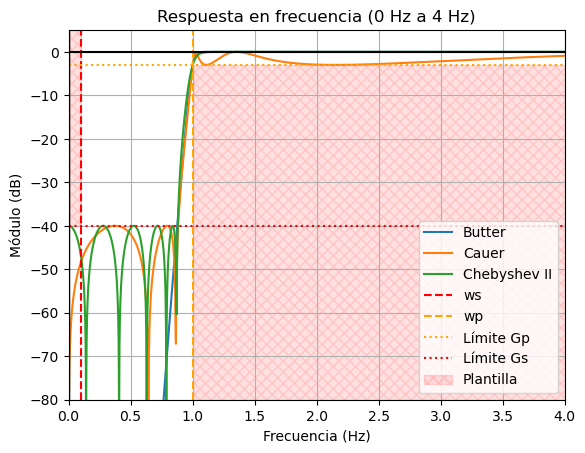

In [9]:
plt.figure(4)

plt.plot(f_butter, 20*np.log10(np.maximum(modulo_butter, 1e-12)),label="Butter")
plt.plot(f_ellip, 20*np.log10(np.maximum(modulo_ellip, 1e-12)),label="Cauer")
plt.plot(f_cheby, 20*np.log10(np.maximum(modulo_cheby, 1e-12)),label="Chebyshev II")

plt.title("Respuesta en frecuencia (0 Hz a 4 Hz)")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(ws1, color="red", linestyle="--", label="ws")
plt.axvline(wp1, color="orange", linestyle="--", label="wp")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-80, 5)
y_min, y_max = plt.ylim()

plt.fill_between([0, ws1], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.fill_between([ws2, fs_ecg/2], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.xlim(0, 4)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

Podemos apreciar que efectivamente todos los filtros realizados cumplen con la totalidad de las restricciones de una manera prácticamente perfecta. Sin embargo, el aproximador de máxima planicidad pareciera ser el que cumple por demás con lo pedido, ya que es el que menos cerca se encuentra de las zonas prohibidas en todo momento y se asegura de que atenuar lo que tiene que filtrar. Esto no lo vuelve mejor filtro directamente, ya que seguramente esto venga con un costo computacional o complejidad de armado asociado.

Podemos ver como, además, Chebyshev II introduce oscilaciones en la banda de rechazo, mientras que Cauer presenta este efecto de ripple incluso en la banda de paso, introduciendo atenuación en la misma, aunque este dentro de los valores permitidos.

Por el lado de la fase, podemos ver cómo Cauer y Butter presentan un desfasaje lineal a partir de la frecuencia superior de stop, aunque presenta cambios de pendiente en los puntos donde se produce un cero de transmisión, lo que generará que el retardo no sea continuo. De igual manera, en la zona de paso, la fase de ningún filtro tiene un comportamiento lineal, lo cual generará que las distintas frecuencias de la señal tengan un retardo distinto. Veamos lo que sucede con el retardo de cada caso.

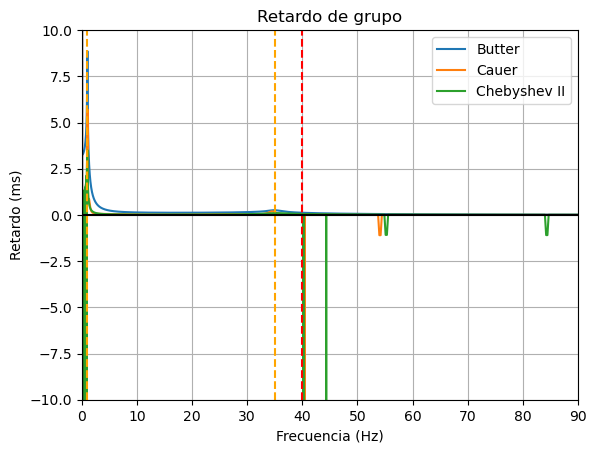

In [10]:
plt.figure(5)

plt.title("Retardo de grupo")

plt.plot(f_butter, retardo_butter, label="Butter")
plt.plot(f_ellip, retardo_ellip, label="Cauer")
plt.plot(f_cheby, retardo_cheby, label="Chebyshev II")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.ylabel("Retardo (ms)")
plt.xlabel("Frecuencia (Hz)")
plt.xlim(0, ws2+50)
plt.ylim(-10,10)

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

Efectivamente, en el retardo se aprecia lo que esperabamos ver. En la banda de paso ninguno de los filtros presenta un retardo constante. Esto es un inconveniente, dado que las distintas componentes de la señal tendrán un retardo distinto, generando deformaciones en la señal que filtremos. Que tengan fase lineal a partir de la frecuencia de paso no nos es de especial interés, ya que justamente estas frecuencias ya deberían estar lo suficientemente atenuadas para que no tengan ningún efecto sobre la señal resultante.

Como análisis final, veamos cuántos bloques SOS fueron necesarios para cada filtro.

In [11]:
print("Cantidad de SOS del Butterworth: ", sos_butter.shape)
print("Cantidad de SOS del Cauer: ", sos_ellip.shape)
print("Cantidad de SOS del Chebyshev II: ", sos_cheby.shape)

Cantidad de SOS del Butterworth:  (33, 6)
Cantidad de SOS del Cauer:  (5, 6)
Cantidad de SOS del Chebyshev II:  (10, 6)


Podemos ver que el Butterworth fue el más complejo, ya que se necesita de 33 bloques para poder lograr las restricciones, lo cuál también concuerda con que de analizamos previamente. Del mismo modo, el Cauer es el más sencillo, siendo el que ondula mas constantemente muy cerca de la zona prohibida.

Con este último análisis podemos decir que de estos filtros, si lo que más nos preocupa es que se cumplan las restricciones de módulo sin importar la complejidad, probablemente el Butterworth resulte el más útil. Sin embargo, en aplicaciones donde el rendimiento sea lo mas importante, el Cauer presenta una muy baja complejidad y una buena respuesta.

## Diseño filtros FIR
Continuando con los filtros de respuesta finita, nuevamente realizamos la función general para todos los filtros. En este caso la función que genera los coeficientes no puede estar incluida, ya que cada tipo de filtro FIR tiene una función de Python diferente para hacerlo. Entonces, en este caso, debemos pasarle los coeficiente, las frecuencias sobre las cuales calcular la respuesta y la frecuencia de sampleo.

In [12]:
def filtro_FIR(b,ff,fs):
    f, H = signal.freqz(b, worN = ff,fs=fs)
    modulo = np.abs(H)
    fase = np.unwrap(np.angle(H))
    retardo = np.full_like(f, (len(b) - 1) / 2 * 1000 / fs_ecg)
    return f, modulo, fase, retardo

Ahora, nuevamente declaramos la condiciones de diseño en el formato que requieren estas funciones. Para esto indicamos las frecuencias de interés y sus respectivas ganancias deseadas, en este caso en veces. Además debemos indicar los taps, es decir, la cantidad de coeficientes que tendrá cada filtro. En este caso elegimos 2001 para el de ventana y 1001 para el de cuadrados mínimos, en base a probar con distintos valores y ser el que mejor lograba una buena relación entre complejidad y cumplir con el diseño, además de ser una cantidad impar para lograr que sea un filtro de clase I. En cambio, para el PMR debimos poner 1001 por su naturaleza ondulatoria, ya que unos coeficientes menos generaba que en la zona de paso las oscilaciones toquen la zona prohibida, mientras que mas coeficientes provocaba ganancias superiores a 1 en la zona entre la wp2 y la ws2.

In [13]:
ws1=0.1
wp1=1
wp2 = 35
ws2 = 40

freqs = [0.0,ws1,wp1,wp2+2,ws2,fs_ecg/2]
gains = [0.0,0.0,1.0,1.0,0.0,0.0]

taps_win = 2001
taps_firls = 1001
taps_PMR= 1001

Con estos valores ya podemos calcular los coeficientes necesarios para cada tipo de filtro. Cada uno a su vez tiene otras especificaciones necesarias. En el caso del de ventana, es necesario indicar que tipo de ventana queremos utilizar. En este caso elegimos la de Hamming por su relación de compromiso entre el ancho del lóbulo principal y la atenuación de los lóbulos secundarios. Como ya hemos visto en trabajos anteriores, Hamming permite reducir las oscilaciones espectrales manteniendo un ancho de transición relativamente moderado. Además de que, en general, Hamming suele ser una elección clásica para este tipo de señales.

Por otro lado, tanto el método de cuadrados mínimos como el de Remez piden un vector de pesos, es decir, qué tan importante será una restricción a la hora de calcular el error ponderado de qué tanto se diferencia nuestro filtro del ideal. En ambos casos pedimos que se pondere más las zonas de rechazo, ya que al tener zonas pequeñas, principalmente en baja frecuencia, es especialmente importante que estas restricciones se cumplan. Con el caso de PMR debimos poner una ponderación no tan alta, porque si no nuevamente empezaba a presentar oscilaciones muy fuertes en la zona de paso.

In [14]:
b_ls = signal.firls(taps_firls, freqs,gains,weight=[500,1.0,500],fs=fs_ecg)
b_win_hamming=signal.firwin2(taps_win,freqs, gains, window="hamming", fs=fs_ecg)
b_PMR = signal.remez(taps_PMR,freqs,[0,1,0],weight=[20,1.0,20],fs=fs_ecg)

Otro detalle que debemos prestar atención es que a la función que calcula la transferencia de cada filtro hay que darle los valores de frecuencia en los que tiene que calcular. Estos puntos los haremos más densos en las zonas de transición, donde los cambios serán más bruscos, mientras que en el resto de zonas podremos tomar menos. Por esa razón, al momento de graficar, se verán ciertos cambios abruptos aunque continuos en aquellos en los que no se aplique el *logspace*.

In [15]:
ff = np.append(np.logspace(np.log10(0.001),np.log10(1),2000),np.linspace(1.001,35,2000))
ff = np.append(ff,np.logspace(np.log10(35.001),np.log10(45),2000))
ff = np.append(ff,np.linspace(45.1,fs_ecg/2,2000))

Calculamos las funciones transferencia de cada filtro.

In [16]:
f_ls, modulo_ls, fase_ls, retardo_ls = filtro_FIR(b_ls, ff, fs_ecg)
f_hamming, modulo_hamming, fase_hamming, retardo_hamming = filtro_FIR(b_win_hamming, ff, fs_ecg)
f_PMR, modulo_PMR, fase_PMR, retardo_PMR = filtro_FIR(b_PMR, ff, fs_ecg)

Y realizamos los gráficos del módulo y de la fase de los tres.

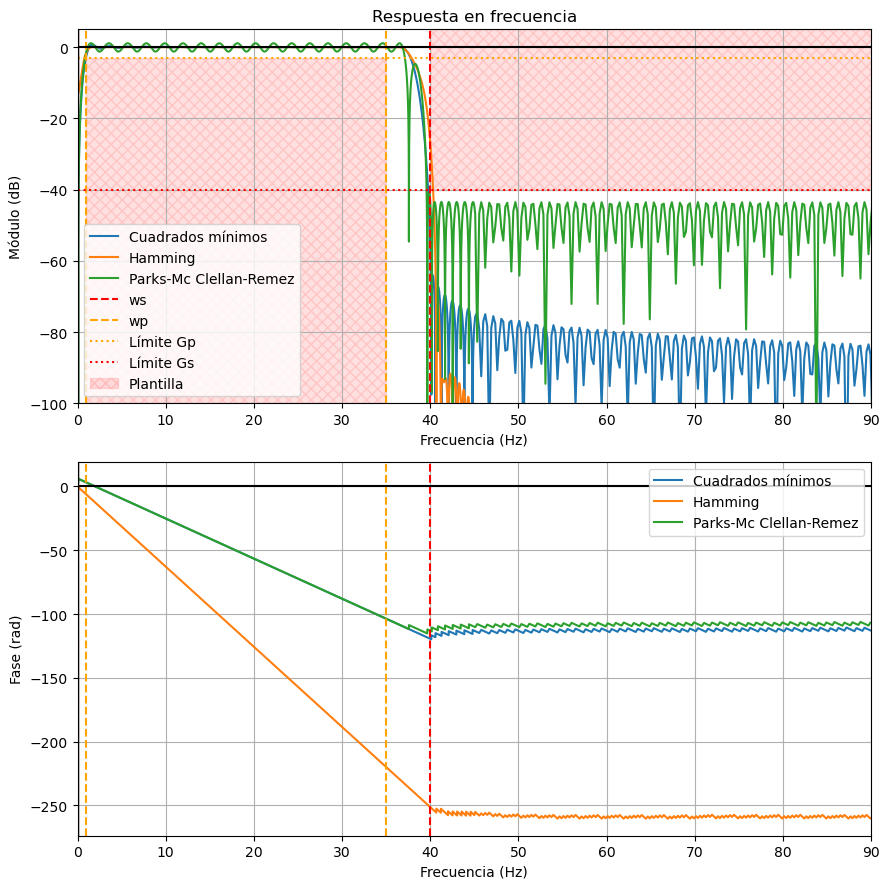

In [17]:
plt.figure(6, figsize=(9,9))

plt.subplot(2,1,1)

plt.plot(f_ls, 20*np.log10(np.maximum(modulo_ls, 1e-12)),label="Cuadrados mínimos")
plt.plot(f_hamming, 20*np.log10(np.maximum(modulo_hamming, 1e-12)),label="Hamming")
plt.plot(f_PMR, 20*np.log10(np.maximum(modulo_PMR, 1e-12)),label="Parks-Mc Clellan-Remez")

plt.title("Respuesta en frecuencia")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(ws1, color="red", linestyle="--", label="ws")
plt.axvline(wp1, color="orange", linestyle="--", label="wp")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-100, 5)
y_min, y_max = plt.ylim()

plt.fill_between([0, ws1], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.fill_between([ws2, fs_ecg/2], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.xlim(0, ws2+50)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()


plt.subplot(2,1,2)

plt.plot(f_ls, fase_ls, label="Cuadrados mínimos")
plt.plot(f_hamming, fase_hamming, label="Hamming")
plt.plot(f_PMR, fase_PMR, label="Parks-Mc Clellan-Remez")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.ylabel("Fase (rad)")
plt.xlabel("Frecuencia (Hz)")

plt.xlim(0, ws2+50)

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

plt.tight_layout()

Podemos ver cómo la respuesta en frecuencia de los 3 cumple en gran medida con lo pedido. Hamming pareciera estar atravesando las zonas prohibidas de stop tanto a derecha como a izquierda, pero no por mucho. También, se aprecia lo que mencionábamos previamente de la PMR en la banda de paso, donde presenta un comportamiento ondulatorio al rededor de 0 dB, mientras que los otros filtros sí presentan una transferencia más continua en el cero. Veamos qué pasa en las zonas de transición.

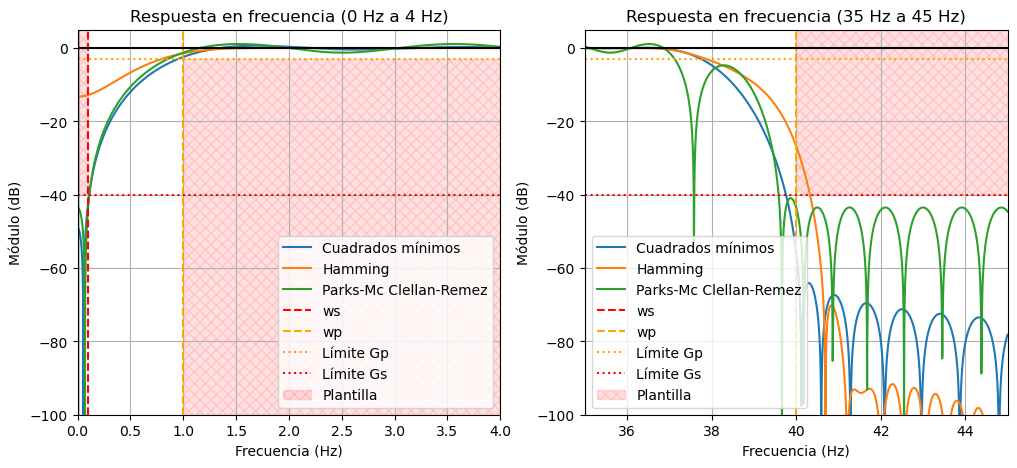

In [18]:
plt.figure(7, figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(f_ls, 20*np.log10(np.maximum(modulo_ls, 1e-12)),label="Cuadrados mínimos")
plt.plot(f_hamming, 20*np.log10(np.maximum(modulo_hamming, 1e-12)),label="Hamming")
plt.plot(f_PMR, 20*np.log10(np.maximum(modulo_PMR, 1e-12)),label="Parks-Mc Clellan-Remez")

plt.title("Respuesta en frecuencia (0 Hz a 4 Hz)")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(ws1, color="red", linestyle="--", label="ws")
plt.axvline(wp1, color="orange", linestyle="--", label="wp")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-100, 5)
y_min, y_max = plt.ylim()

plt.fill_between([0, ws1], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.xlim(0, 4)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

plt.subplot(1,2,2)

plt.plot(f_ls, 20*np.log10(np.maximum(modulo_ls, 1e-12)),label="Cuadrados mínimos")
plt.plot(f_hamming, 20*np.log10(np.maximum(modulo_hamming, 1e-12)),label="Hamming")
plt.plot(f_PMR, 20*np.log10(np.maximum(modulo_PMR, 1e-12)),label="Parks-Mc Clellan-Remez")

plt.title("Respuesta en frecuencia (35 Hz a 45 Hz)")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(wp2, color="red", linestyle="--", label="ws")
plt.axvline(ws2, color="orange", linestyle="--", label="wp")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-100, 5)
y_min, y_max = plt.ylim()

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.fill_between([ws2, fs_ecg/2], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.xlim(35, 45)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

Efectivamente, Hamming incumple la condición de filtrado en baja frecuencia, mientras que la de alta frecuencia incumple fuertemente entre 40 Hz y 41 Hz, pero es la que más atenúa para frecuencias mas altas.

Por otro lado, la fase de los tres concuerdan con lo que esperaríamos de un filtro FIR, también llamados de fase lineal. Presentan una fase de pendiente constante, asociada a la cantidad de taps según la siguiente formula:
\begin{equation}
Pendiente  = M = \frac{N-1}{2}
\end{equation}
Este valor también será el que tendremos como retardo en milisegundos gracias a nuestra frecuencia de sampleo de 1 kHz. También podemos ver que existen pequeñas discontinuidades de salto, que a diferencia de los filtros IIR que analizamos, sí se dan de manera instantánea, lo que permite que la fase sea lineal. Nuevamente estas discontinuidades se dan en los ceros de transmisión. Veamos lo que sucede con el retardo.

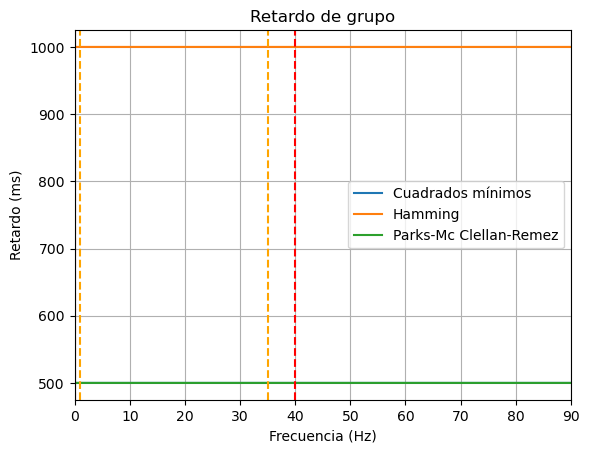

In [19]:
plt.figure(8)

plt.plot(f_ls, retardo_ls, label="Cuadrados mínimos")
plt.plot(f_hamming, retardo_hamming, label="Hamming")
plt.plot(f_PMR, retardo_PMR, label="Parks-Mc Clellan-Remez")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.title("Retardo de grupo")
plt.ylabel("Retardo (ms)")
plt.xlabel("Frecuencia (Hz)")
plt.xlim(0, ws2+50)

plt.grid()
plt.legend()

Efectivamente, el retardo es continuo y tiene una estrecha relación con la cantidad de coeficientes de cada filtro. Por esto es que Hamming, que era el de mayor cantidad de taps, es también el que presenta mayor retardo. Esta es la mayor utilidad de estos filtros, saber que sin importar como lo diseñemos el retardo será continuo para todas las frecuencias.

Nuevamente, si debemos elegir uno estos filtros para esta plantilla específica, pareciera ser que el de cuadrados mínimos es el que mejor cumple con todas las especificaciones, también con un retardo aceptable.

## Análisis de filtros FIR e IIR juntos

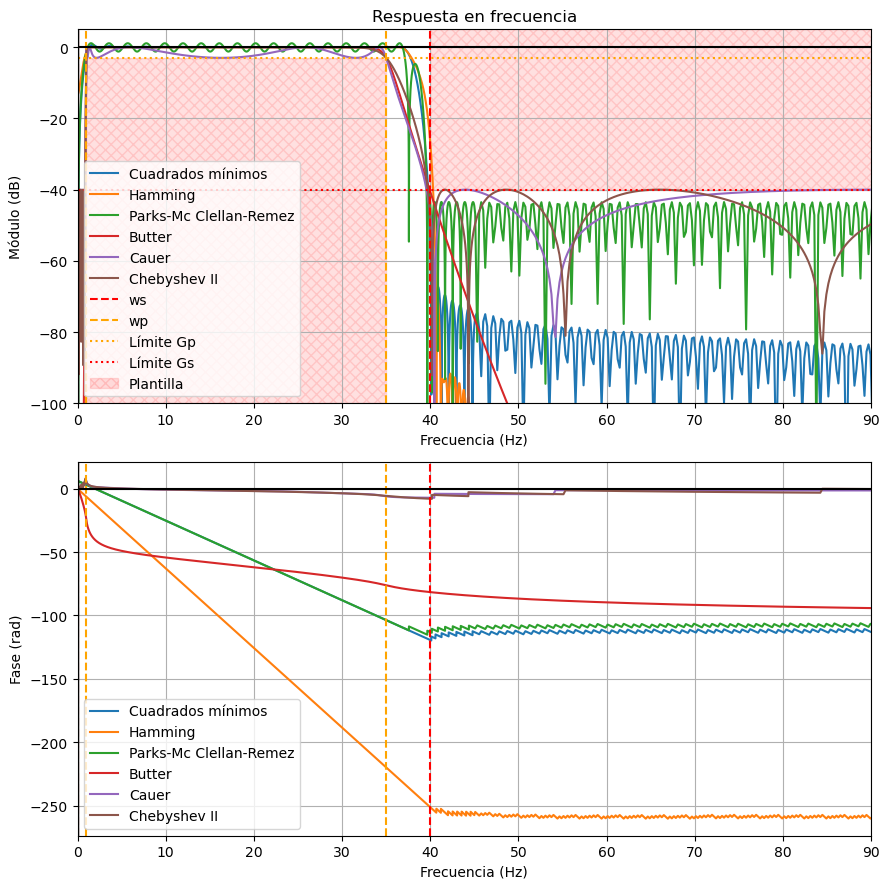

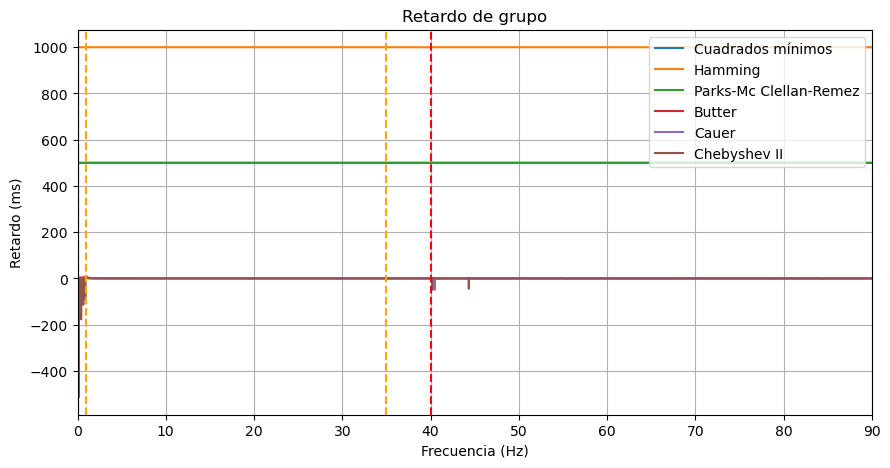

In [20]:
plt.figure(9, figsize=(9,9))

plt.subplot(2,1,1)

plt.plot(f_ls, 20*np.log10(np.maximum(modulo_ls, 1e-12)),label="Cuadrados mínimos")
plt.plot(f_hamming, 20*np.log10(np.maximum(modulo_hamming, 1e-12)),label="Hamming")
plt.plot(f_PMR, 20*np.log10(np.maximum(modulo_PMR, 1e-12)),label="Parks-Mc Clellan-Remez")
plt.plot(f_butter, 20*np.log10(np.maximum(modulo_butter, 1e-12)),label="Butter")
plt.plot(f_ellip, 20*np.log10(np.maximum(modulo_ellip, 1e-12)),label="Cauer")
plt.plot(f_cheby, 20*np.log10(np.maximum(modulo_cheby, 1e-12)),label="Chebyshev II")

plt.title("Respuesta en frecuencia")
plt.ylabel("Módulo (dB)")
plt.xlabel("Frecuencia (Hz)")

plt.axvline(ws1, color="red", linestyle="--", label="ws")
plt.axvline(wp1, color="orange", linestyle="--", label="wp")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.axhline(-G_p, color="orange", linestyle=":", label="Límite Gp")
plt.axhline(-G_s, color="red", linestyle=":", label="Límite Gs")

plt.ylim(-100, 5)
y_min, y_max = plt.ylim()

plt.fill_between([0, ws1], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.fill_between([wp1, wp2], y_min, -G_p,color="red", alpha=0.12,hatch="xxx", edgecolor="red",label="Plantilla")

plt.fill_between([ws2, fs_ecg/2], -G_s, y_max,color="red", alpha=0.12,hatch="xxx", edgecolor="red")

plt.xlim(0, ws2+50)
plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()


plt.subplot(2,1,2)

plt.plot(f_ls, fase_ls, label="Cuadrados mínimos")
plt.plot(f_hamming, fase_hamming, label="Hamming")
plt.plot(f_PMR, fase_PMR, label="Parks-Mc Clellan-Remez")
plt.plot(f_butter, fase_butter, label="Butter")
plt.plot(f_ellip, fase_ellip, label="Cauer")
plt.plot(f_cheby, fase_cheby, label="Chebyshev II")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.ylabel("Fase (rad)")
plt.xlabel("Frecuencia (Hz)")

plt.xlim(0, ws2+50)

plt.axhline(0,color="black")
plt.axvline(0,color="black",linewidth=1)

plt.grid()
plt.legend()

plt.tight_layout()


plt.figure(10,figsize=(10.25,5))

plt.plot(f_ls, retardo_ls, label="Cuadrados mínimos")
plt.plot(f_hamming, retardo_hamming, label="Hamming")
plt.plot(f_PMR, retardo_PMR, label="Parks-Mc Clellan-Remez")
plt.plot(f_butter, retardo_butter, label="Butter")
plt.plot(f_ellip, retardo_ellip, label="Cauer")
plt.plot(f_cheby, retardo_cheby, label="Chebyshev II")

plt.axvline(ws1, color="red", linestyle="--")
plt.axvline(wp1, color="orange", linestyle="--")
plt.axvline(wp2, color="orange", linestyle="--")
plt.axvline(ws2, color="red", linestyle="--")

plt.title("Retardo de grupo")
plt.ylabel("Retardo (ms)")
plt.xlabel("Frecuencia (Hz)")
plt.xlim(0, ws2+50)

plt.grid()
plt.legend()

Lo primero que nos parece importante destacar teniendo todos los filtros es analizar el retardo. En este gráfico los retardos de los filtros IIR parecen lineales, aunque antes veíamos que no lo era, lo cuál se da porque las variaciones que veíamos se producían al rededor del cero con saltos de discontinuidad, lo cuál en esta escala ya no se aprecia y pareciera ser lineal. Lo mismo seguramente pase en las señales filtradas. Si bien una fase no lineal provocará deformaciones en la señal resultante, estos desfasajes probablemente sean muy chicos y sean perceptibles pero no destructivos. En cambio, los métodos de respuesta finita tendrán un desfasaje muy alto en comparación, con la ventaja de que al ser constante será mucho mas fácil poder corregir la señal filtrada.

Por el lado de la amplitud consideramos que no hay mucho más para decir que no haya sido mencionado previamente, las ventajas y desventajas de cada método permanece y, según nuestra consideración para este caso, los mejores filtros siguen siendo los mismos.

## Implementación de los filtros IIR
A continuación, se le aplicará finalmente cada filtro analizado previamente a nuestra señal de electrocardiograma. En cuanto a los sistemas de respuesta infinita al impulso, se utilizará la función *sosfilt*, la cual tomará los coeficientes previamente calculados y devolverá la señal ya filtrada del ECG.

De modo de facilitar la detección de los cambios previo y posterior al filtrado de la señal, se tomaron dos zonas de interés con sus respectivas perturbaciones.

In [21]:
y_b = signal.sosfilt(sos_butter,ecg_one_lead_audio)
y_e = signal.sosfilt(sos_ellip,ecg_one_lead_audio)
y_c = signal.sosfilt(sos_cheby,ecg_one_lead_audio)
x = np.arange(0,len(ecg_one_lead_audio)+1,1)

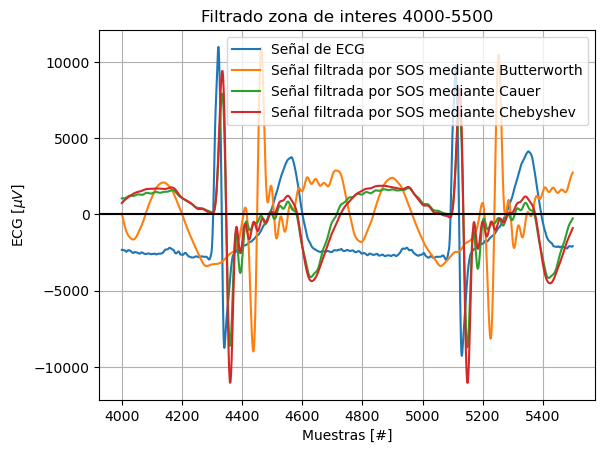

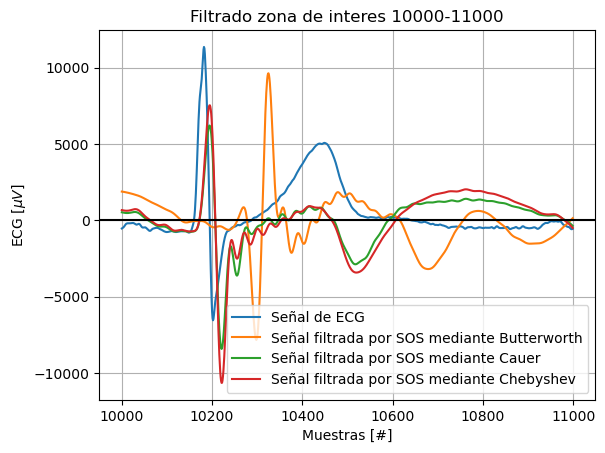

In [22]:
plt.figure(11)

plt.title("Filtrado zona de interes 4000-5500")

plt.plot(x[4000:5500],ecg_one_lead_audio[4000:5500],label='Señal de ECG')
plt.plot(x[4000:5500],y_b[4000:5500],label='Señal filtrada por SOS mediante Butterworth')
plt.plot(x[4000:5500],y_e[4000:5500],label='Señal filtrada por SOS mediante Cauer')
plt.plot(x[4000:5500],y_c[4000:5500],label='Señal filtrada por SOS mediante Chebyshev')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()


plt.figure(12)

plt.title("Filtrado zona de interes 10000-11000")

plt.plot(x[10000:11000],ecg_one_lead_audio[10000: 11000],label='Señal de ECG')
plt.plot(x[10000:11000],y_b[10000: 11000],label='Señal filtrada por SOS mediante Butterworth')
plt.plot(x[10000:11000],y_e[10000: 11000],label='Señal filtrada por SOS mediante Cauer')
plt.plot(x[10000:11000],y_c[10000: 11000],label='Señal filtrada por SOS mediante Chebyshev')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

A simple vista, no es sencillo percibir las modificaciones, debido al desfasaje no lineal característico de los sistemas IIR. Igualmente, aquí se evidencia el parecido en el retardo de Cauer y de Chebyshev y la gran distinción en el retraso temporal del Butterworth.

Con el fin de remediar esto, se puede utilizar otra función, *sosfiltfilt*, la cual genera una reconstrucción de un filtro sin desfase neto, y de un orden el doble mayor a la del original, permitiendo una mejor comparación entre las señales. Como el retardo de grupo no es constante, no es posible corregir esto con una simple suma.

Sin embargo, hay que tener en cuenta que este procedimiento tambíen modifica la respuesta de módulo, ya que la ganancia pasa a ser el doble de la ganancia esperada, si lo expresamos en dB.

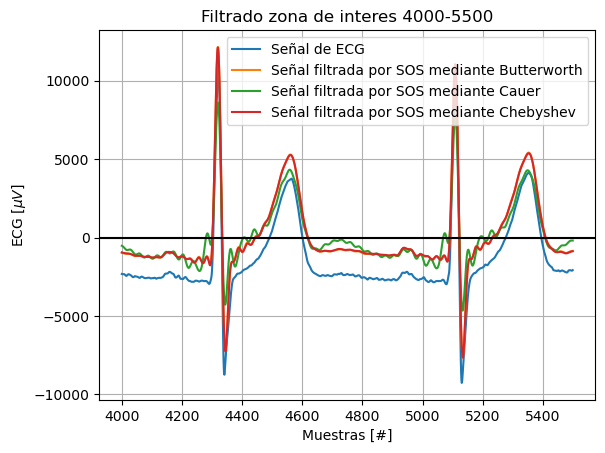

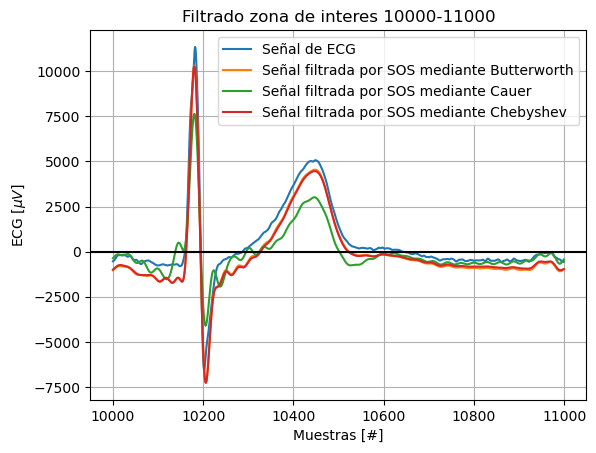

In [23]:
y_b = signal.sosfiltfilt(sos_butter,ecg_one_lead_audio)
y_e = signal.sosfiltfilt(sos_ellip,ecg_one_lead_audio)
y_c = signal.sosfiltfilt(sos_cheby,ecg_one_lead_audio)
x = np.arange(0,len(ecg_one_lead_audio)+1,1)

plt.figure(13)

plt.title("Filtrado zona de interes 4000-5500")

plt.plot(x[4000:5500],ecg_one_lead_audio[4000:5500],label='Señal de ECG')
plt.plot(x[4000:5500],y_b[4000:5500],label='Señal filtrada por SOS mediante Butterworth')
plt.plot(x[4000:5500],y_e[4000:5500],label='Señal filtrada por SOS mediante Cauer')
plt.plot(x[4000:5500],y_c[4000:5500],label='Señal filtrada por SOS mediante Chebyshev')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()


plt.figure(14)

plt.title("Filtrado zona de interes 10000-11000")

plt.plot(x[10000:11000],ecg_one_lead_audio[10000: 11000],label='Señal de ECG')
plt.plot(x[10000:11000],y_b[10000: 11000],label='Señal filtrada por SOS mediante Butterworth')
plt.plot(x[10000:11000],y_e[10000: 11000],label='Señal filtrada por SOS mediante Cauer')
plt.plot(x[10000:11000],y_c[10000: 11000],label='Señal filtrada por SOS mediante Chebyshev')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

Se puede observar cómo en la primer zona los tres métodos IIR evidencian una mejora en cuanto la cercanía con el eje de abscisas. Sin embargo, no se consigue una alineación óptima debido al margen reducido entre las primeras frecuencias de paso y de stop. Si se ampliara este rango, probablemente se atenuarían aspectos relevantes de la señal original. Además, especialmente en el caso del método de Cauer, se pueden observar ondulaciones no presentes en la señal original, rodeando el complejo QRS y la onda T, mientras que Chebyshev aparenta tener mayor semejanza con el electrocardiograma posterior a la onda T. En cuanto a la segunda zona, se ven nuevamente los mismos comportamientos, sumado a que el filtrado mediante Cauer aparenta ser más agresivo y genera una atenuación innecesaria en cada onda.

Un detalle no menor, es la manera en que la señal filtrada por el IIR de máxima planicidad es casi imperceptible en ambas zonas. Esto se puede adjudicar a la gran semejanza que tiene con el método de Chebyshev, que, de no haber aplicado la función *sosfiltfilt*, no se habría destacado. Su diferencia principal recae en la velocidad en que opera cada uno, cualidad en la que predomina Chebyshev. Sin embargo, dejando de lado el desfasaje de cada uno, demuestran comportamientos casi idénticos al momento de filtrar.

A fin de observar un panorama más amplio de la señal, se graficará una tercer zona:

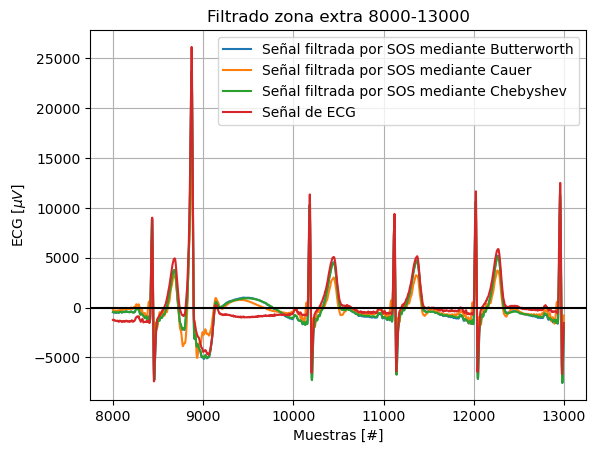

In [24]:
plt.figure(15)

plt.title("Filtrado zona extra 8000-13000")

plt.plot(x[8000:13000],y_b[8000:13000],label='Señal filtrada por SOS mediante Butterworth')
plt.plot(x[8000:13000],y_e[8000:13000],label='Señal filtrada por SOS mediante Cauer')
plt.plot(x[8000:13000],y_c[8000:13000],label='Señal filtrada por SOS mediante Chebyshev')
plt.plot(x[8000:13000],ecg_one_lead_audio[8000:13000],label='Señal de ECG')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

En este rango del ECG, observamos varios latidos normales y uno anormal, de alta energía registrada en la onda R. Luego de este, parece una señal limpia, e igualmente, se advierten alteraciones post filtrado. No solo el elíptico provoca una atenuación de alta frecuencia en las ondas T, sino que además los tres filtros IIR generan cierta separación del eje x, por lo que las bajas frecuencias también se ven afectadas por estos métodos. Consecuentemente, no se podría establecer un buen rendimiento por parte de estos instrumentos, ya que, por un lado, no demostraron ser ideales al momento de la corrección de interferencias en la señal, y por el otro, no se vieron inadvertidas en zonas del ECG sin perturbaciones aparentes, es decir, que modificaron la señal cuando no era deseado.

## Implementación de los filtros FIR
De la misma manera, se analizará los comportamientos de los sistemas de Respuesta al Impulso Finita ante la señal de electrocardiograma. Aquí, se utilizará la función *lfilter*, a la cual se le indican los coeficientes *b* calculados mediante *firwin2*, los coeficientes *a* ya normalizados (evaluados a 1) y la señal a filtrar.

Al igual que antes, se estudiarán ciertas zonas de interés.

In [25]:
ecg_hamming = signal.lfilter(b_win_hamming,1.0, ecg_one_lead_audio)
ecg_ls = signal.lfilter(b_ls,1.0, ecg_one_lead_audio)
ecg_PMR = signal.lfilter(b_PMR,1.0, ecg_one_lead_audio)

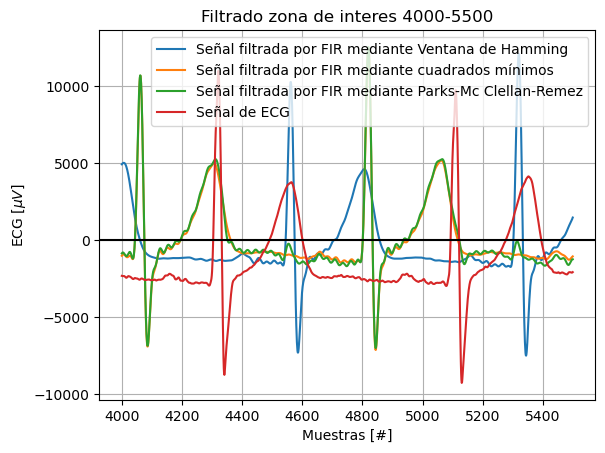

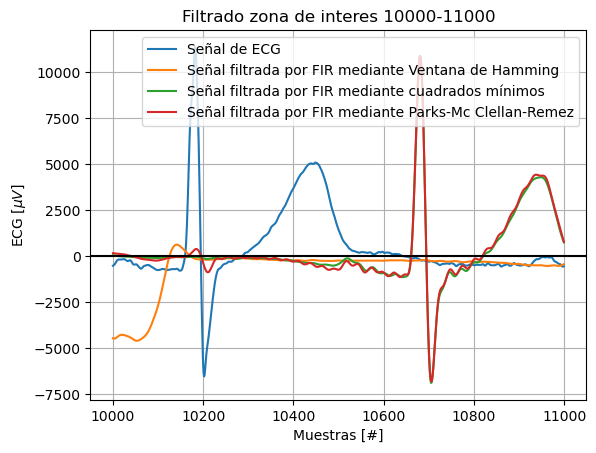

In [26]:
plt.figure(16)

plt.title("Filtrado zona de interes 4000-5500")

plt.plot(x[4000:5500],ecg_hamming[4000:5500],label='Señal filtrada por FIR mediante Ventana de Hamming')
plt.plot(x[4000:5500],ecg_ls[4000:5500],label='Señal filtrada por FIR mediante cuadrados mínimos')
plt.plot(x[4000:5500],ecg_PMR[4000:5500],label="Señal filtrada por FIR mediante Parks-Mc Clellan-Remez")
plt.plot(x[4000:5500],ecg_one_lead_audio[4000:5500],label='Señal de ECG')


plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()


plt.figure(17)

plt.title("Filtrado zona de interes 10000-11000")

plt.plot(x[10000:11000],ecg_one_lead_audio[10000: 11000],label='Señal de ECG')
plt.plot(x[10000:11000],ecg_hamming[10000: 11000],label='Señal filtrada por FIR mediante Ventana de Hamming')
plt.plot(x[10000:11000],ecg_ls[10000: 11000],label='Señal filtrada por FIR mediante cuadrados mínimos')
plt.plot(x[10000:11000],ecg_PMR[10000: 11000],label="Señal filtrada por FIR mediante Parks-Mc Clellan-Remez")

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

A diferencia de los IIR, los FIR tienen una demora de grupo constante, como se demostró en las figuras de las plantillas. Entonces, se ve cómo la señal entera se ve desplazada temporalmente de manera uniforme. Además, los filtros mediante la PMR y cuadrados mínimos comprueban el desfasaje idéntico en su implementación, por la manera en que se superponen casi idénticamente. Se buscará, entonces, quitar el desfasaje, para así comparar la señal original con cada una de las filtradas. Se empleará la fórmula descripta anteriormente, sobre la relación entre el retraso y la cantidad de coeficientes del sistema.

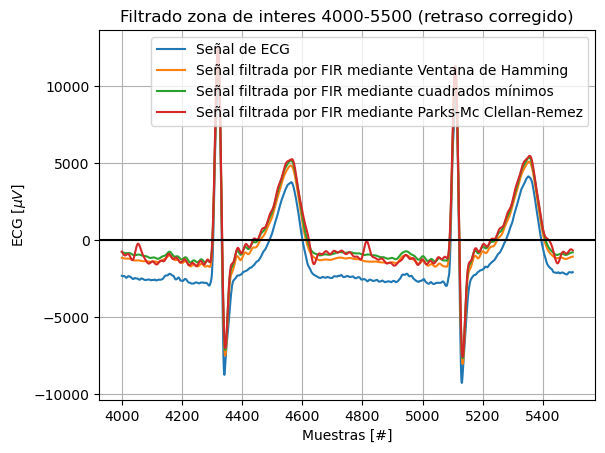

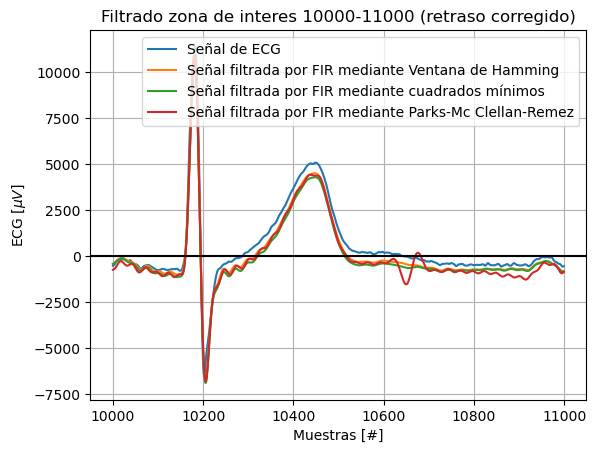

In [27]:
retraso_ls = (taps_firls-1)//2
retraso_win = (taps_win-1)//2
retraso_PMR = (taps_PMR-1)//2

plt.figure(18)

plt.title("Filtrado zona de interes 4000-5500 (retraso corregido)")

plt.plot(x[4000:5500],ecg_one_lead_audio[4000:5500],label='Señal de ECG')
plt.plot(x[4000:5500],ecg_hamming[4000+retraso_win:5500+retraso_win],label='Señal filtrada por FIR mediante Ventana de Hamming')
plt.plot(x[4000:5500],ecg_ls[4000+retraso_ls:5500+retraso_ls],label='Señal filtrada por FIR mediante cuadrados mínimos')
plt.plot(x[4000:5500],ecg_PMR[4000+retraso_PMR:5500+retraso_PMR],label="Señal filtrada por FIR mediante Parks-Mc Clellan-Remez")

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()


plt.figure(19)

plt.title("Filtrado zona de interes 10000-11000 (retraso corregido)")

plt.plot(x[10000:11000],ecg_one_lead_audio[10000: 11000],label='Señal de ECG')
plt.plot(x[10000:11000],ecg_hamming[10000+retraso_win: 11000+retraso_win],label='Señal filtrada por FIR mediante Ventana de Hamming')
plt.plot(x[10000:11000],ecg_ls[10000+retraso_ls: 11000+retraso_ls],label='Señal filtrada por FIR mediante cuadrados mínimos')
plt.plot(x[10000:11000],ecg_PMR[10000+retraso_PMR: 11000+retraso_PMR],label="Señal filtrada por FIR mediante Parks-Mc Clellan-Remez")

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

En las zonas de interés se pueden observar ciertas características, algunas parecidas a la implementación de los IIR y otras distintas. Primero, es notoria la falta de ripple del filtro mediante Hamming, en comparación con aquel presente en cuadrados mínimos y en Parks-Mc Clellan. A pesar de la atenuación generada por este FIR, se aprecia que se mantuvo la onda P. Así mismo, ocurre lo mismo que antes, en cuanto al aumento de la cercanía al eje de abscisas, aunque no a la perfección. Los tres métodos cuentan someramente con los mismos comportamientos.

En la segunda zona de interés se destacan aún más las ondulaciones innecesarias provocadas por el filtro de diseño óptimo. Además, los tres tipos de FIR producen cierta atenuación en la onda T, manifestando nuevamente la mitigación de las altas frecuencias.

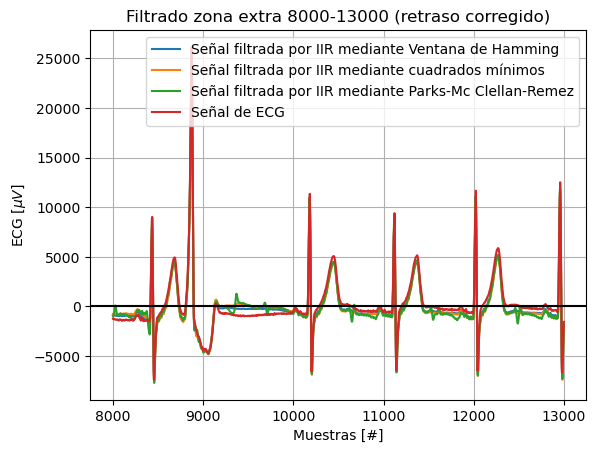

In [28]:
plt.figure(20)

plt.title("Filtrado zona extra 8000-13000 (retraso corregido)")

plt.plot(x[8000:13000],ecg_hamming[8000+retraso_win: 13000+retraso_win],label='Señal filtrada por IIR mediante Ventana de Hamming')
plt.plot(x[8000:13000],ecg_ls[8000+retraso_ls: 13000+retraso_ls],label='Señal filtrada por IIR mediante cuadrados mínimos')
plt.plot(x[8000:13000],ecg_PMR[8000+retraso_PMR: 13000+retraso_PMR],label="Señal filtrada por IIR mediante Parks-Mc Clellan-Remez")
plt.plot(x[8000:13000],ecg_one_lead_audio[8000: 13000],label='Señal de ECG')

plt.xlabel("Muestras [#]")
plt.ylabel("ECG [$\mu V$]")

plt.axhline(0,color="black")
plt.grid()

plt.legend()

Al igual que antes, tomamos una tercer zona de mayor rango de muestras, para determinar la efectividad de nuestros filtros.

Es sencillo determinar que uno de los fenómenos antes vistos ocurre aquí también; las señales filtradas provocan cierto alejamiento del eje x indeseado de manera que aumenta cada vez más. En este caso, las altas frecuencias parecen casi inadvertidas por los filtros, aunque en la segunda zona de interés se ve cierta modificación. Por lo tanto, se podría decir que estos filtrados generan menor distorsión en zonas donde no hay interferentes para frecuencias altas, pero sí para aquellas de frecuencias bajas. A la vez, no cumple en su totalidad con la corrección de elementos contaminantes.

# Conclusión
En este trabajo se diseñaron y compararon tanto filtros digitales FIR como IIR en su generalidad, analizando el cumplimiento de una plantilla, sus desfasajes y el correcto filtrado de una señal de ECG. A la vez, se contrastaron de ambos tipos de sistemas cada método aplicado, siendo que, a pesar de pertenecer a un mismo grupo característico, aún así presentaban diferencias entre sí.

Los sistemas de Respuesta al Impulso Infinita exhibieron un comportamiento de fase no lineal. La gran diferencia entre ellas se destaca no en su cumplimiento de las restricciones establecidas, si no en el orden que requirieron. En este detalle fue que pudimos observar como Butterworth presentó mayor complejidad, mientras que Cauer permitió alcanzar los objetivos con menor cantidad de SOS. En cambio, este último presentó un gran número de oscilaciones en su respuesta en frecuencia, característico de este tipo de filtros, lo cuál puede no ser ideal si deseamos una respuesta de modulo más lineal en la banda de paso, algo que los otros filtros si permiten.

Los sistemas de Respuesta al Impulso Finita se distinguieron principalmente por el retardo de grupo con el que contó cada uno, y, por el otro lado, la complejidad de su manipulación al momento del ajuste de datos para la plantilla. El método de Parks-Mc Clellan-Remez es aquel que más complicaciones conllevó, ya que, contrario a razonamiento lógico, a medida que se aumentaban los *taps_PMR*, peor era el sistema. Por lo tanto, se le mantuvo una cantidad relativamente baja, al igual que para el método de cuadrados mínimos. Esto luego se vio diréctamente reflejado en la magnitud del retardo. En cuanto a la implementación en el ECG, los tres filtros contaron aproximadamente con las mismas cualidades, aunque se vio que Hamming reaalizaba una mitigación de cierto ripple de la señal, mientras que el método de diseño óptimo en algunos casos lo acentuaba más.

Finalmente, entre FIR e IIR como conjuntos, se evidenciaron varios factores diferentes. Primero, a pesar de la alinealidad de la fase, los sistemas IIR mantenían un retardo notablemente menor a que los FIR, lo que también se translada a la variación en el costo computacional. Segundo, con respecto al rendimiento de cada uno, una vez aplicado a la señal ninguno fue al cien por ciento efectivo, ya que no fueron del todo capaces de eliminar la linea base o incluso generando artefactos en zonas donde previamente no se presentaba ruido apreciable. Igualmente, podría decirse que, en cuanto a las altas frecuencias, los IIR mostraron mayor irregularidad. Por lo tanto, la elección del método más adecuado depende del compromiso entre la reducción de interferencias y la preservación de la información útil de la señal.